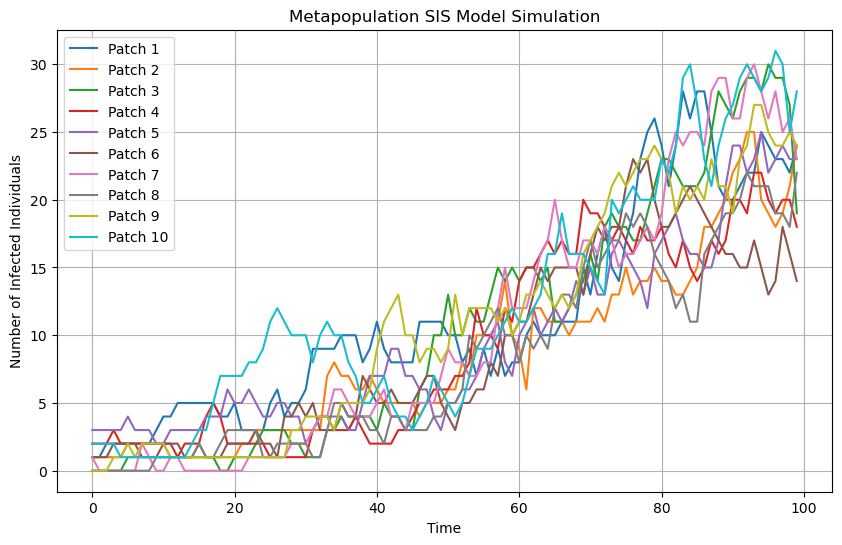

In [12]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
from enum import Enum, auto

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

class SISModel:
    def __init__(self, N, population_per_patch, beta, mu, 
                 p, timesteps, initial_infected, alpha, average_degree):
        self.N = N
        self.population_per_patch = population_per_patch
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.timesteps = timesteps
        self.initial_infected = initial_infected
        self.average_degree = average_degree

        self.patches = np.zeros((N, population_per_patch))
        self.infection_history = np.zeros((timesteps, N))

        self.rho = np.zeros(N)  # 先初始化 self.rho
        
        self.G = nx.watts_strogatz_graph(N, average_degree, 0.8)

        # 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        N = self.W.shape[0]
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

        self._initialize_patches()

    def _initialize_patches(self):
        for i in range(self.N):
            infected_indices = np.random.choice(self.population_per_patch, self.initial_infected, replace=False)
            self.patches[i, infected_indices] = 1
            # get initial rho of each patch
            self.rho[i] = np.sum(self.patches[i]) / self.population_per_patch

    def _get_Pi_i(self):
        # 计算Πi
        R_i = np.zeros(self.N)
        D_i = np.zeros(self.N)
        P_i = np.zeros(self.N)
        Pi_i = np.zeros(self.N)
        new_rho = np.zeros(self.N)
        # 计算每个patch中的感染率
        for i in range(self.N):
            R_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.average_degree * self.rho[j] for j in range(self.N)]))
            D_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.population_per_patch * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.population_per_patch * self.rho[j] for j in 
                                            range(self.N)]))
            P_i[i] = self.alpha * R_i[i] + (1 - self.alpha) * D_i[i]
            # Πi = infection_probabilities
        for i in range(N):
            Pi_i[i] = (1 - self.p) * P_i[i] + self.p * np.sum([self.C[i, j] * P_i[j] for j in range(self.N)])
            new_rho[i] = (1 - mu) * self.rho[i] + (1 - self.rho[i]) * Pi_i[i]
        # 更新rho
        self.Pi_i = Pi_i
        self.rho = new_rho
        return Pi_i

    def _infection_process(self, patch_index, current_patch):

        for j in range(self.population_per_patch):
            if current_patch[j] == 0 and np.random.rand() < self.Pi_i[patch_index]:
                current_patch[j] = 1
        return current_patch

    def _recovery_process(self, current_patch):
        for j in range(self.population_per_patch):
            if current_patch[j] == 1 and np.random.rand() < self.mu:
                current_patch[j] = 0
        return current_patch

    # def _migration_process(self, current_patch, patch_index):
    #     for j in range(self.population_per_patch):
    #         if np.random.rand() < self.p:
    #             target_patch = np.random.randint(self.N)
    #             if target_patch != patch_index:
    #                 self.patches[target_patch][np.random.randint(self.population_per_patch)] = current_patch[j]
    #                 current_patch[j] = 0
    #     return current_patch

    def run_simulation(self):
        for t in range(self.timesteps):
            self._get_Pi_i()
            for i in range(self.N):
                current_patch = self.patches[i]
                current_patch = self._infection_process(i,current_patch)
                current_patch = self._recovery_process(current_patch)
                # current_patch = self._migration_process(current_patch, i)
                
                self.patches[i] = current_patch
                self.infection_history[t, i] = np.sum(current_patch)

    def plot_results(self):
        plt.figure(figsize=(10, 6))
        for i in range(self.N):
            plt.plot(self.infection_history[:, i], label=f'Patch {i+1}')
        plt.xlabel('Time')
        plt.ylabel('Number of Infected Individuals')
        plt.legend()
        plt.title('Metapopulation SIS Model Simulation')
        plt.grid(True)
        plt.show()

# 参数设置
N = 10
population_per_patch = 100
beta = 0.0035
mu = 0.1
p = 0.1
timesteps = 100
initial_infected = 1
alpha = 0.6
average_degree = 5


# 运行模拟
model = SISModel(N=N, population_per_patch=population_per_patch, beta=beta,
                 mu=mu, p=p, timesteps=timesteps, initial_infected=initial_infected, alpha=alpha, average_degree=average_degree)
model.run_simulation()
model.plot_results()


N个种群的平均感染个体变化情况

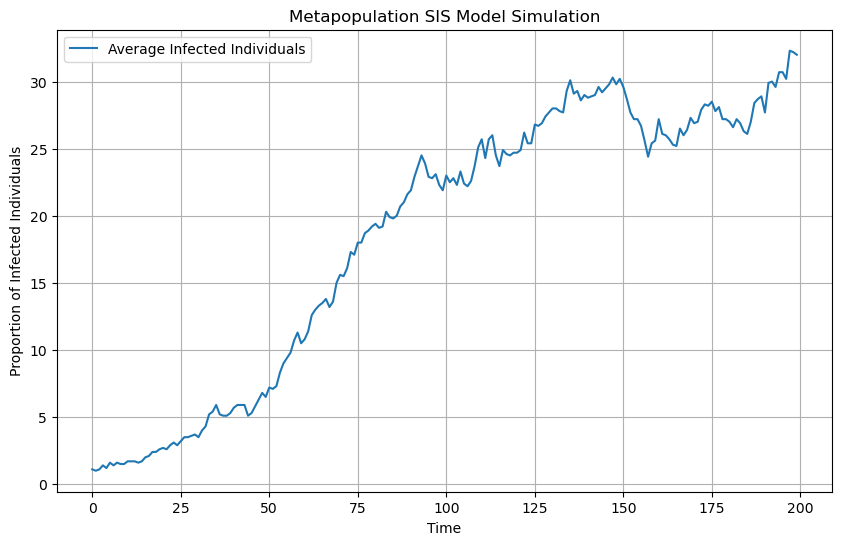

In [21]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
from enum import Enum, auto

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

class SISModel:
    def __init__(self, N, population_per_patch, beta, mu, 
                 p, timesteps, initial_infected, alpha, average_degree):
        self.N = N
        self.population_per_patch = population_per_patch
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.timesteps = timesteps
        self.initial_infected = initial_infected
        self.average_degree = average_degree

        self.patches = np.zeros((N, population_per_patch))
        self.infection_history = np.zeros((timesteps, N))
        self.rho = np.zeros(N)  # 先初始化 self.rho

        self.G = nx.watts_strogatz_graph(N, average_degree, 0.8)

        # 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

        self._initialize_patches()

    def _initialize_patches(self):
        for i in range(self.N):
            infected_indices = np.random.choice(self.population_per_patch, self.initial_infected, replace=False)
            self.patches[i, infected_indices] = 1
            # get initial rho of each patch
            self.rho[i] = np.sum(self.patches[i]) / self.population_per_patch

    def _get_Pi_i(self):
        # 计算Πi
        R_i = np.zeros(self.N)
        D_i = np.zeros(self.N)
        P_i = np.zeros(self.N)
        Pi_i = np.zeros(self.N)
        new_rho = np.zeros(self.N)
        # 计算每个patch中的感染率
        for i in range(self.N):
            R_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.average_degree * self.rho[j] for j in range(self.N)]))
            D_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.population_per_patch * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.population_per_patch * self.rho[j] for j in 
                                            range(self.N)]))
            P_i[i] = self.alpha * R_i[i] + (1 - self.alpha) * D_i[i]
            # Πi = infection_probabilities
        for i in range(self.N):
            Pi_i[i] = (1 - self.p) * P_i[i] + self.p * np.sum([self.C[i, j] * P_i[j] for j in range(self.N)])
            new_rho[i] = (1 - self.mu) * self.rho[i] + (1 - self.rho[i]) * Pi_i[i]
        # 更新rho
        self.Pi_i = Pi_i
        self.rho = new_rho
        return Pi_i

    def _infection_process(self, patch_index, current_patch):

        for j in range(self.population_per_patch):
            if current_patch[j] == 0 and np.random.rand() < self.Pi_i[patch_index]:
                current_patch[j] = 1
        return current_patch

    def _recovery_process(self, current_patch):
        for j in range(self.population_per_patch):
            if current_patch[j] == 1 and np.random.rand() < self.mu:
                current_patch[j] = 0
        return current_patch

    def run_simulation(self):
        self.average_infection_history = np.zeros(self.timesteps)  # 新增记录平均感染个体数量
        for t in range(self.timesteps):
            self._get_Pi_i()
            for i in range(self.N):
                current_patch = self.patches[i]
                current_patch = self._infection_process(i, current_patch)
                current_patch = self._recovery_process(current_patch)
                
                self.patches[i] = current_patch
                self.infection_history[t, i] = np.sum(current_patch)
            # 记录每个时间步的平均感染个体数量
            self.average_infection_history[t] = np.mean(self.infection_history[t, :])  

    def plot_results(self):
        plt.figure(figsize=(10, 6))
        # plt.plot(self.average_infection_history, self.average_infection_history/self.population_per_patch,label='Average Infected Individuals')
        # plt.ylim(0, 1)  # 设置y轴范围
        plt.plot(self.average_infection_history, label='Average Infected Individuals')
        plt.xlabel('Time')
        plt.ylabel('Proportion of Infected Individuals')
        plt.legend()
        plt.title('Metapopulation SIS Model Simulation')
        plt.grid(True)
        plt.show()

# 参数设置
N = 10
population_per_patch = 100
beta = 0.0035
mu = 0.1
p = 0.1
timesteps = 200
initial_infected = 1
alpha = 0.6
average_degree = 5

# 运行模拟
model = SISModel(N=N, population_per_patch=population_per_patch, beta=beta,
                 mu=mu, p=p, timesteps=timesteps, initial_infected=initial_infected, alpha=alpha, average_degree=average_degree)
model.run_simulation()
model.plot_results()


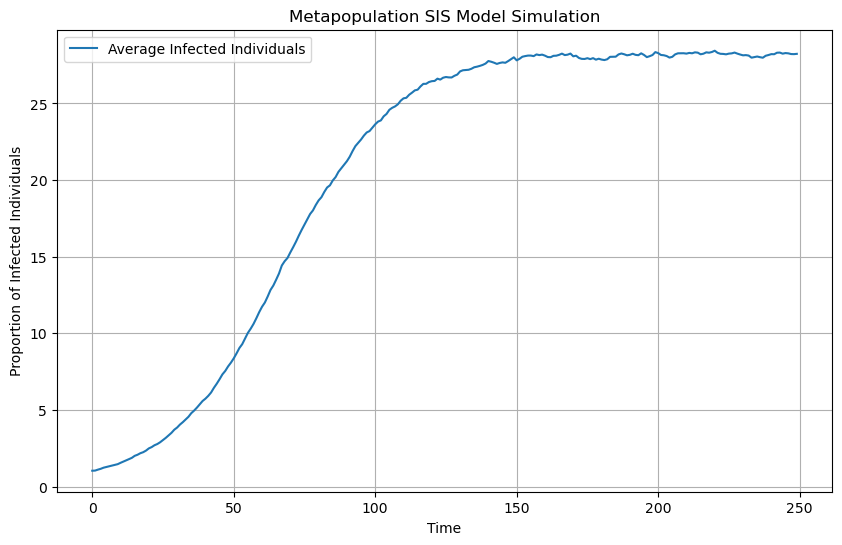

In [28]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

class SISModel:
    def __init__(self, N, population_per_patch, beta, mu, 
                 p, timesteps, initial_infected, alpha, average_degree):
        self.N = N
        self.population_per_patch = population_per_patch
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.timesteps = timesteps
        self.initial_infected = initial_infected
        self.average_degree = average_degree

        self.patches = np.zeros((N, population_per_patch))
        self.infection_history = np.zeros((timesteps, N))
        self.rho = np.zeros(N)  # 先初始化 self.rho

        self.G = nx.watts_strogatz_graph(N, average_degree, 0.8)

        # 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

        self._initialize_patches()

    def _initialize_patches(self):
        for i in range(self.N):
            infected_indices = np.random.choice(self.population_per_patch, self.initial_infected, replace=False)
            self.patches[i, infected_indices] = 1
            # get initial rho of each patch
            self.rho[i] = np.sum(self.patches[i]) / self.population_per_patch

    def _get_Pi_i(self):
        # 计算Πi
        R_i = np.zeros(self.N)
        D_i = np.zeros(self.N)
        P_i = np.zeros(self.N)
        Pi_i = np.zeros(self.N)
        new_rho = np.zeros(self.N)
        # 计算每个patch中的感染率
        for i in range(self.N):
            R_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.average_degree * self.rho[j] for j in range(self.N)]))
            D_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.population_per_patch * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.population_per_patch * self.rho[j] for j in 
                                            range(self.N)]))
            P_i[i] = self.alpha * R_i[i] + (1 - self.alpha) * D_i[i]
            # Πi = infection_probabilities
        for i in range(self.N):
            Pi_i[i] = (1 - self.p) * P_i[i] + self.p * np.sum([self.C[i, j] * P_i[j] for j in range(self.N)])
            new_rho[i] = (1 - self.mu) * self.rho[i] + (1 - self.rho[i]) * Pi_i[i]
        # 更新rho
        self.Pi_i = Pi_i
        self.rho = new_rho
        return Pi_i

    def _infection_process(self, patch_index, current_patch):

        for j in range(self.population_per_patch):
            if current_patch[j] == 0 and np.random.rand() < self.Pi_i[patch_index]:
                current_patch[j] = 1
        return current_patch

    def _recovery_process(self, current_patch):
        for j in range(self.population_per_patch):
            if current_patch[j] == 1 and np.random.rand() < self.mu:
                current_patch[j] = 0
        return current_patch

    def run_simulation(self):
        self.average_infection_history = np.zeros(self.timesteps)  # 新增记录平均感染个体数量
        for t in range(self.timesteps):
            self._get_Pi_i()
            for i in range(self.N):
                current_patch = self.patches[i]
                current_patch = self._infection_process(i, current_patch)
                current_patch = self._recovery_process(current_patch)
                
                self.patches[i] = current_patch
                self.infection_history[t, i] = np.sum(current_patch)
            # 记录每个时间步的平均感染个体数量
            self.average_infection_history[t] = np.mean(self.infection_history[t, :])  

    def plot_results(self, average_results):
        plt.figure(figsize=(10, 6))
        plt.plot(average_results, label='Average Infected Individuals')
        plt.xlabel('Time')
        plt.ylabel('Proportion of Infected Individuals')
        plt.legend()
        plt.title('Metapopulation SIS Model Simulation')
        plt.grid(True)
        plt.show()

# 参数设置
N = 10
population_per_patch = 100
beta = 0.0035
mu = 0.1
p = 0.1
timesteps = 250
initial_infected = 1
alpha = 0.6
average_degree = 5
num_simulations = 100

# 运行模拟并取平均
all_simulation_results = np.zeros((num_simulations, timesteps))

for i in range(num_simulations):
    model = SISModel(N=N, population_per_patch=population_per_patch, beta=beta,
                     mu=mu, p=p, timesteps=timesteps, initial_infected=initial_infected, alpha=alpha, average_degree=average_degree)
    model.run_simulation()
    all_simulation_results[i, :] = model.average_infection_history

average_results = np.mean(all_simulation_results, axis=0)

# 绘制平均结果
model.plot_results(average_results)


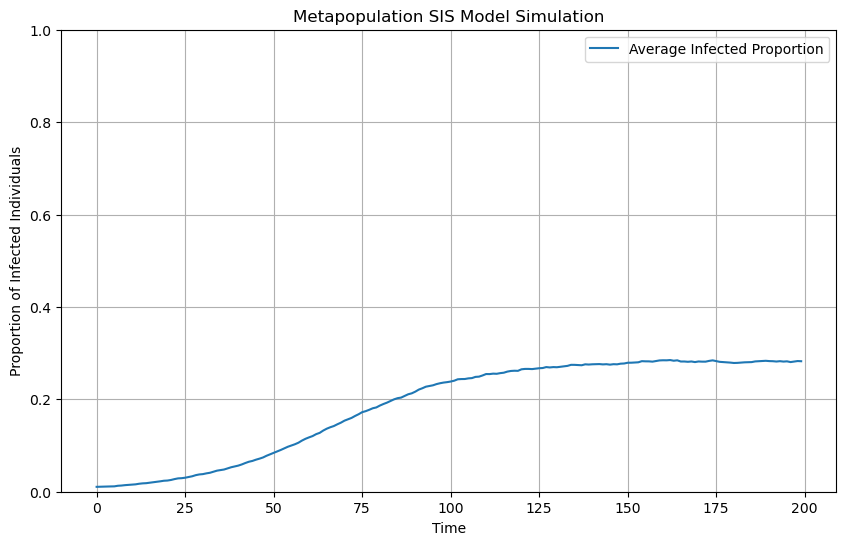

In [29]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

class SISModel:
    def __init__(self, N, population_per_patch, beta, mu, 
                 p, timesteps, initial_infected, alpha, average_degree):
        self.N = N
        self.population_per_patch = population_per_patch
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.timesteps = timesteps
        self.initial_infected = initial_infected
        self.average_degree = average_degree

        self.patches = np.zeros((N, population_per_patch))
        self.infection_history = np.zeros((timesteps, N))
        self.rho = np.zeros(N)  # 先初始化 self.rho

        self.G = nx.watts_strogatz_graph(N, average_degree, 0.8)

        # 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

        self._initialize_patches()

    def _initialize_patches(self):
        for i in range(self.N):
            infected_indices = np.random.choice(self.population_per_patch, self.initial_infected, replace=False)
            self.patches[i, infected_indices] = 1
            # get initial rho of each patch
            self.rho[i] = np.sum(self.patches[i]) / self.population_per_patch

    def _get_Pi_i(self):
        # 计算Πi
        R_i = np.zeros(self.N)
        D_i = np.zeros(self.N)
        P_i = np.zeros(self.N)
        Pi_i = np.zeros(self.N)
        new_rho = np.zeros(self.N)
        # 计算每个patch中的感染率
        for i in range(self.N):
            R_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.average_degree * self.rho[j] for j in range(self.N)]))
            D_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.population_per_patch * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.population_per_patch * self.rho[j] for j in 
                                            range(self.N)]))
            P_i[i] = self.alpha * R_i[i] + (1 - self.alpha) * D_i[i]
            # Πi = infection_probabilities
        for i in range(self.N):
            Pi_i[i] = (1 - self.p) * P_i[i] + self.p * np.sum([self.C[i, j] * P_i[j] for j in range(self.N)])
            new_rho[i] = (1 - self.mu) * self.rho[i] + (1 - self.rho[i]) * Pi_i[i]
        # 更新rho
        self.Pi_i = Pi_i
        self.rho = new_rho
        return Pi_i

    def _infection_process(self, patch_index, current_patch):

        for j in range(self.population_per_patch):
            if current_patch[j] == 0 and np.random.rand() < self.Pi_i[patch_index]:
                current_patch[j] = 1
        return current_patch

    def _recovery_process(self, current_patch):
        for j in range(self.population_per_patch):
            if current_patch[j] == 1 and np.random.rand() < self.mu:
                current_patch[j] = 0
        return current_patch

    def run_simulation(self):
        self.average_infection_history = np.zeros(self.timesteps)  # 新增记录平均感染个体数量
        for t in range(self.timesteps):
            self._get_Pi_i()
            for i in range(self.N):
                current_patch = self.patches[i]
                current_patch = self._infection_process(i, current_patch)
                current_patch = self._recovery_process(current_patch)
                
                self.patches[i] = current_patch
                self.infection_history[t, i] = np.sum(current_patch) / self.population_per_patch  # 比例而不是数量
            # 记录每个时间步的平均感染个体比例
            self.average_infection_history[t] = np.mean(self.infection_history[t, :])  

    def plot_results(self, average_results):
        plt.figure(figsize=(10, 6))
        plt.plot(average_results, label='Average Infected Proportion')
        plt.xlabel('Time')
        plt.ylabel('Proportion of Infected Individuals')
        plt.ylim(0, 1)  # 设置y轴范围
        plt.legend()
        plt.title('Metapopulation SIS Model Simulation')
        plt.grid(True)
        plt.show()

# 参数设置
N = 10
population_per_patch = 100
beta = 0.0035
mu = 0.1
p = 0.1
timesteps = 200
initial_infected = 1
alpha = 0.6
average_degree = 5
num_simulations = 50

# 运行模拟并取平均
all_simulation_results = np.zeros((num_simulations, timesteps))

for i in range(num_simulations):
    model = SISModel(N=N, population_per_patch=population_per_patch, beta=beta,
                     mu=mu, p=p, timesteps=timesteps, initial_infected=initial_infected, alpha=alpha, average_degree=average_degree)
    model.run_simulation()
    all_simulation_results[i, :] = model.average_infection_history

average_results = np.mean(all_simulation_results, axis=0)

# 绘制平均结果
model.plot_results(average_results)
